# Previne Brasil: previsão de municípios com ISF abaixo de 9

## 1. Problema

O Previne Brasil foi o modelo de financiamento da atenção primária entre 2020 e 2024. No componente de pagamento por desempenho, o Ministério da Saúde acompanhava sete indicadores por município a cada quadrimestre. Cada indicador recebe uma nota de 0 a 10 de acordo com a distância até a meta, e a média ponderada dessas notas é o Indicador Sintético Final (ISF). O valor repassado é proporcional ao ISF: um município com ISF 8 recebe 80% do incentivo.

Escolhemos essa base porque ela tem a mesma estrutura da gratificação por desempenho da SESAU Recife, que é o tema do projeto (indicadores com meta, nota e peso que formam um resultado geral), mas é pública e cobre os 5.570 municípios do país.

**Objetivo:** prever, ao final de um quadrimestre, quais municípios terão ISF abaixo de 9 no quadrimestre seguinte, ou seja, vão receber menos de 90% do incentivo.

**Tipo de problema:** classificação binária.

**Target:** `abaixo_90`, igual a 1 quando o ISF do quadrimestre seguinte é menor que 9.

Usamos o quadrimestre seguinte como alvo porque o ISF do mesmo quadrimestre é calculado a partir das notas que entrariam como atributos, e um modelo treinado assim só reproduziria a fórmula. Com os atributos do quadrimestre `t` e o alvo em `t+1`, o modelo precisa prever um resultado que ainda não foi medido.

**Uso possível:** uma secretaria estadual ou um apoiador regional pode usar a probabilidade prevista para decidir quais municípios acompanhar primeiro. Os casos mais difíceis de identificar sem modelo são os municípios que hoje têm ISF acima de 9 e vão cair, porque eles não aparecem como problema no quadrimestre atual.

Como referência, usamos um baseline que repete o resultado atual: ele prevê `abaixo_90 = 1` para quem já está abaixo de 9. Como o ISF muda pouco de um quadrimestre para o outro, esse baseline já acerta bastante.

## 2. Dados (resumo)

- Fonte: Portal de Dados Abertos do Ministério da Saúde, conjunto "Indicadores de desempenho do Programa Previne Brasil", licença CC BY-ND 3.0. Os arquivos ficam em `ml/data/previne/` e não são versionados.
- Um CSV por quadrimestre de 2024 (Q1, Q2 e Q3), separado por `;`.
- Cada linha corresponde a um município, um quadrimestre, um indicador e uma visão de equipe.
- As metas vêm das notas técnicas de 2022 e os pesos do manual instrutivo do financiamento da APS. Os PDFs estão em `ml/data/previne/regras/`.
- Os dados são agregados por município e não têm informação de pessoas.

### Estrutura do caderno

Depois das seções de problema, dados e preparação, o caderno segue a ordem pedida nas diretrizes da AV2: modelagem, experimentos, avaliação, modelo final e conclusões.

| Seção | Conteúdo | Pergunta da apresentação |
| --- | --- | --- |
| 1 e 2 | problema, target e dados | 1 e 2 |
| 3 | análise exploratória | 3 |
| 4 | pré-processamento, features e encoding | 4 |
| 5 | planejamento: algoritmos e métricas | 5 e 7 |
| 6 | modelagem | |
| 7 | experimentos | 6 |
| 8 | avaliação no teste | 8 |
| 9 | modelo final | 9 |
| 10 | importância das features e exemplos de erros | |
| 11 | análise crítica | 10 e 11 |
| 12 | conclusões | todas |

Para rodar, os CSVs precisam estar em `ml/data/previne/`. O caderno funciona a partir da raiz do repositório ou de `ml/notebooks/`.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import lightgbm
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import warnings
warnings.filterwarnings('ignore', message="The argument 'eval_set' is deprecated")

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

### Constantes

`CORTE` é o ISF mínimo para receber 90% do incentivo. `METAS` e `PESOS` são os valores das notas técnicas e do manual instrutivo.

In [3]:
RANDOM_STATE = 42
CORTE = 9

INDICADORES = {10: 'ind1', 20: 'ind2', 30: 'ind3', 40: 'ind4', 50: 'ind5', 70: 'ind7'}
METAS = pd.Series({'ind1': 45, 'ind2': 60, 'ind3': 60, 'ind4': 40, 'ind5': 95, 'ind7': 50})
PESOS = pd.Series({'ind1': 1, 'ind2': 1, 'ind3': 2, 'ind4': 1, 'ind5': 2, 'ind7': 1})

In [4]:
# funciona a partir da raiz do repositório ou de ml/notebooks/
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'ml' / 'data' / 'previne').exists())
arquivos = [RAIZ / 'ml' / 'data' / 'previne' / f'sisab_indicador_desempenho_2024Q{q}.csv' for q in (1, 2, 3)]
df = pd.concat([pd.read_csv(a, sep=';', dtype={'ibge': str}) for a in arquivos], ignore_index=True)

### Estrutura da base

In [5]:
print(df.shape[0], 'registros x', df.shape[1], 'colunas')

descricao = {
    'uf': 'sigla do estado',
    'ibge': 'código IBGE do município',
    'municipio': 'nome do município',
    'nu_competencia': 'último mês do quadrimestre (AAAAMM)',
    'ds_quadrimestre': 'quadrimestre de referência',
    'co_tipo_indicador': 'código do indicador',
    'numerador': 'pessoas do denominador acompanhadas como a nota técnica exige',
    'denominador_utilizador': 'denominador usado no cálculo: o identificado ou o estimado',
    'vl_perc_quad': 'resultado do indicador no quadrimestre (%)',
    'visao_equipe': 'conjunto de equipes considerado: geral, homologadas ou válidas',
    'denominador_identificado': 'pessoas identificadas nos registros da APS',
    'denominador_estimado': 'pessoas estimadas a partir do cadastro e de bases externas',
    'cadastro': 'pessoas cadastradas nas equipes do município',
    'base_externa': 'valor externo usado na estimativa (PNS, SINASC ou estimativa populacional)',
    'percentual': 'identificado sobre estimado (%): abaixo de 85, o cálculo usa o estimado',
    'populacao': 'estimativa populacional do IBGE',
    'dt_criacao_registro': 'data da carga',
}
pd.DataFrame({
    'tipo pandas': df.dtypes.astype(str),
    'valores distintos': df.nunique(),
    'descrição': pd.Series(descricao),
})

300732 registros x 17 colunas


,tipo pandas,valores distintos,descrição
uf,object,27,sigla do estado
ibge,object,5570,código IBGE do município
municipio,object,5298,nome do município
nu_competencia,int64,3,último mês do quadrimestre (AAAAMM)
ds_quadrimestre,object,3,quadrimestre de referência
co_tipo_indicador,int64,6,código do indicador
numerador,int64,8000,pessoas do denominador acompanhadas como a not...
denominador_utilizador,int64,14501,denominador usado no cálculo: o identificado o...
vl_perc_quad,float64,101,resultado do indicador no quadrimestre (%)
visao_equipe,object,3,"conjunto de equipes considerado: geral, homolo..."


In [6]:
pd.crosstab([df['ds_quadrimestre'], df['visao_equipe']], df['co_tipo_indicador'])

co_tipo_indicador               10    20    30    40    50    70
ds_quadrimestre visao_equipe                                    
2024Q1          geral         5570  5570  5570  5570  5570  5570
                homologadas   5570  5570  5570  5570  5570  5570
                validas       5568  5568  5568  5568  5568  5568
2024Q2          geral         5570  5570  5570  5570  5570  5570
                homologadas   5569  5569  5569  5569  5569  5569
                validas       5568  5568  5568  5568  5568  5568
2024Q3          geral         5570  5570  5570  5570  5570  5570
                homologadas   5569  5569  5569  5569  5569  5569
                validas       5568  5568  5568  5568  5568  5568

Três observações sobre a estrutura:

- A base tem seis indicadores (códigos 10, 20, 30, 40, 50 e 70), que correspondem aos indicadores 1, 2, 3, 4, 5 e 7 das notas técnicas. O indicador 6, de hipertensão (peso 2), não está nos dados abertos. Por isso o ISF que calculamos é parcial: seis indicadores com soma de pesos 8, em vez de 10.
- Cada município aparece em três visões de equipe. Ficamos só com `validas`, que é a usada no cálculo do pagamento. Manter as três repetiria cada município três vezes.
- Descartamos `dt_criacao_registro` (um único valor, porque a carga foi feita de uma vez), `nu_competencia` (equivale ao quadrimestre) e `municipio` (repete o código IBGE e tem nomes iguais em estados diferentes: 5.298 nomes para 5.570 códigos).

In [7]:
df = df[df['visao_equipe'] == 'validas'].copy()
df['indicador'] = df['co_tipo_indicador'].map(INDICADORES)
chave = ['ibge', 'uf', 'ds_quadrimestre']

## 3. Análise exploratória

### Distribuição de cada indicador

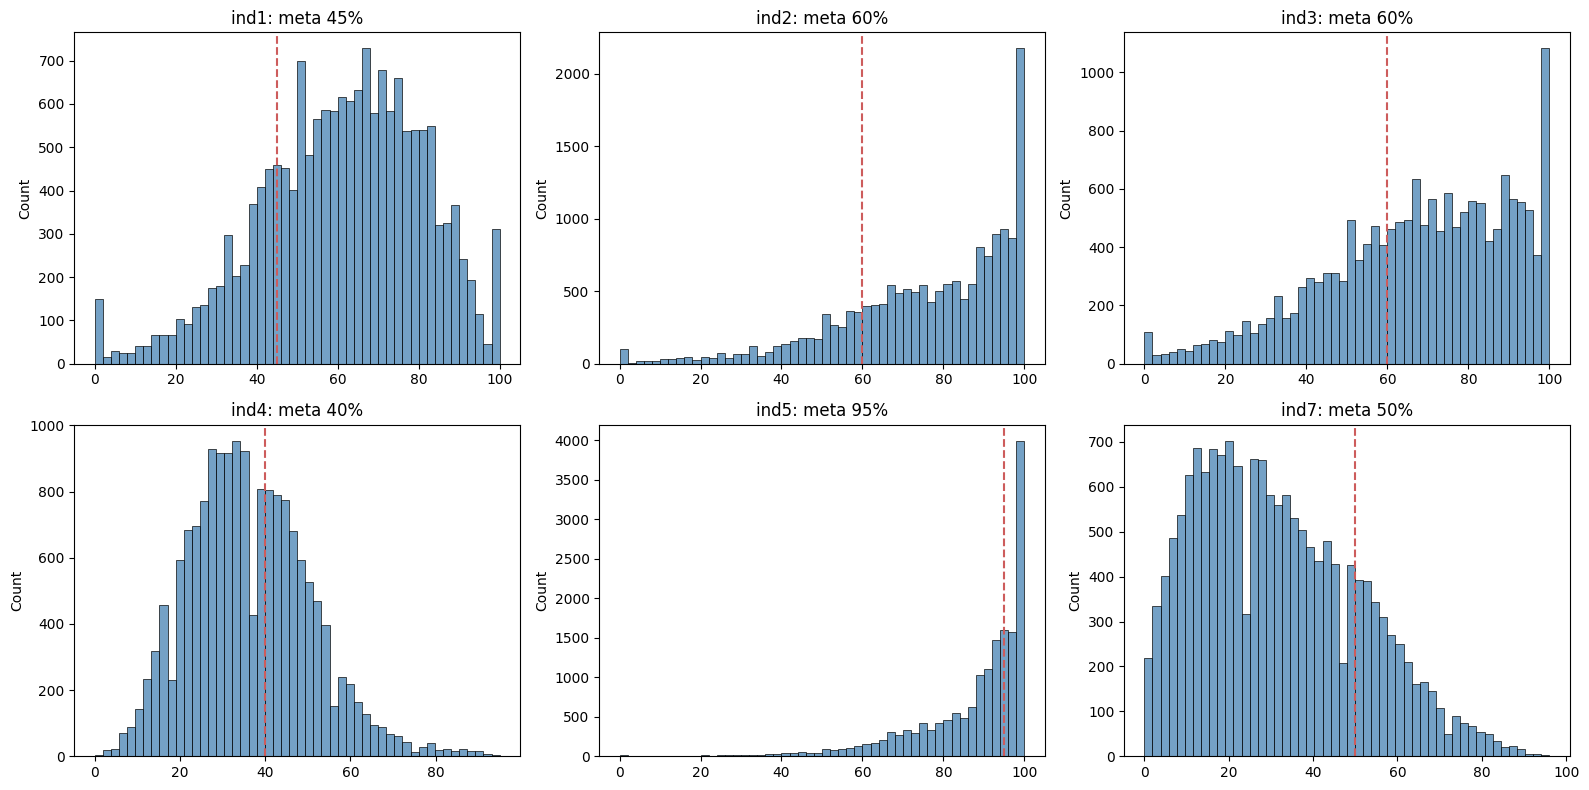

In [8]:
fig, eixos = plt.subplots(2, 3, figsize=(16, 8))
for eixo, (ind, grupo) in zip(eixos.flatten(), df.groupby('indicador')):
    sns.histplot(grupo['vl_perc_quad'], bins=50, ax=eixo, color='steelblue')
    eixo.axvline(METAS[ind], color='indianred', ls='--')
    eixo.set_title(f'{ind}: meta {METAS[ind]}%')
    eixo.set_xlabel('')
plt.tight_layout()
plt.show()

In [9]:
df['bateu_meta'] = df['vl_perc_quad'] >= df['indicador'].map(METAS)
df.groupby(['indicador', 'ds_quadrimestre']).agg(
    mediana=('vl_perc_quad', 'median'),
    bateu_meta=('bateu_meta', 'mean'),
).unstack().round(3)

mediana               bateu_meta              
ds_quadrimestre  2024Q1 2024Q2 2024Q3     2024Q1 2024Q2 2024Q3
indicador                                                     
ind1               64.0   63.0   59.0      0.811  0.806  0.749
ind2               82.0   82.0   75.0      0.825  0.820  0.736
ind3               73.0   71.0   64.0      0.704  0.677  0.576
ind4               35.0   35.0   35.0      0.383  0.398  0.386
ind5               92.0   92.0   91.0      0.398  0.376  0.365
ind7               35.0   29.0   23.0      0.263  0.172  0.147

Os indicadores se dividem em dois grupos. Pré-natal (ind1), sífilis e HIV na gestante (ind2) e saúde bucal da gestante (ind3) estão acima da meta em 58% a 83% dos municípios. Citopatológico (ind4), vacinação (ind5) e diabetes (ind7) estão abaixo da meta em mais de 60%.

A vacinação tem mediana de 92% para uma meta de 95%, então muitos municípios ficam perto da meta sem atingir. Ao mesmo tempo, 19% dos registros de vacinação estão em 100%.

A mediana caiu de Q1 para Q3 em todos os indicadores, menos no citopatológico. A maior queda foi em diabetes, de 35% para 23%, e a fração de municípios que atinge essa meta passou de 26% para 15%.

Os indicadores da gestante têm concentrações em 0 e em 100. Na parte de outliers mostramos que são municípios pequenos, onde uma gestante a mais ou a menos muda o resultado em vários pontos.

### Correlação entre os indicadores

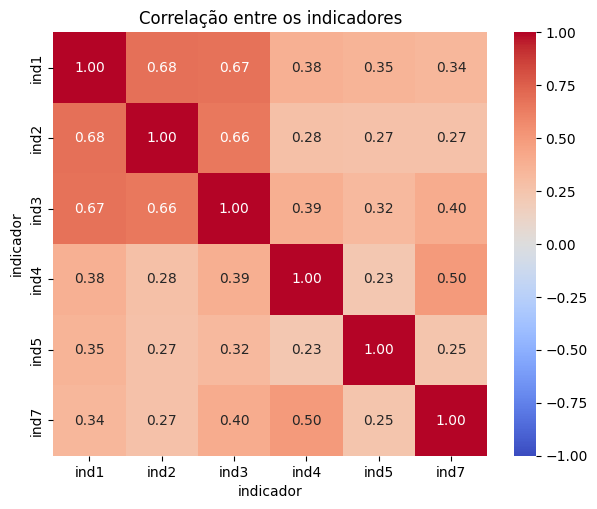

In [10]:
res = df.pivot_table(index=chave, columns='indicador', values='vl_perc_quad')

plt.figure(figsize=(7, 5.5))
sns.heatmap(res.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlação entre os indicadores')
plt.show()

Os três indicadores da gestante têm correlação entre 0,66 e 0,68, o que é esperado, porque partem do mesmo pré-natal e do mesmo denominador. Citopatológico e diabetes têm correlação de 0,50; os dois dependem de consultas registradas pela equipe. A vacinação é o indicador menos correlacionado com os outros (0,23 a 0,35). Nenhum par passa de 0,7, então mantivemos os seis.

### Cálculo do ISF

A nota de cada indicador é `resultado / meta * 10`, limitada a 10, e o ISF é a média das notas ponderada pelos pesos. Antes de aplicar a função na base, conferimos o resultado com o exemplo da Tabela 1 do manual instrutivo, que dá 8,1.

In [11]:
def calcular_isf(resultado, metas, pesos):
    nota = (resultado / metas).clip(upper=1) * 10
    return (nota * pesos).sum(axis=1) / pesos.sum()

exemplo = pd.DataFrame([[70, 60, 55, 40, 80, 25, 30]], columns=[f'ind{i}' for i in range(1, 8)])
metas_manual = pd.Series([60, 60, 60, 40, 95, 50, 50], index=exemplo.columns)
pesos_manual = pd.Series([1, 1, 2, 1, 2, 2, 1], index=exemplo.columns)
assert round(calcular_isf(exemplo, metas_manual, pesos_manual).iloc[0], 1) == 8.1

isf = calcular_isf(res, METAS, PESOS).rename('isf')
isf.groupby('ds_quadrimestre').describe().round(2)

,count,mean,std,min,25%,50%,75%,max
ds_quadrimestre,,,,,,,,
2024Q1,5568.0,8.75,1.27,1.21,8.24,9.08,9.69,10.0
2024Q2,5568.0,8.64,1.28,1.32,8.14,8.97,9.53,10.0
2024Q3,5568.0,8.32,1.39,0.51,7.65,8.64,9.30,10.0


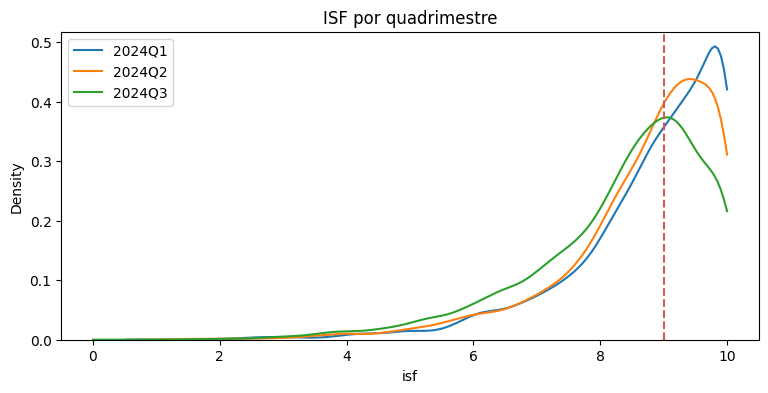

In [12]:
plt.figure(figsize=(9, 4))
for q, grupo in isf.groupby('ds_quadrimestre'):
    sns.kdeplot(grupo, label=q, clip=(0, 10))
plt.axvline(CORTE, color='indianred', ls='--')
plt.title('ISF por quadrimestre')
plt.legend()
plt.show()

O ISF fica concentrado na parte de cima da escala: em Q1 a mediana é 9,08 e um quarto dos municípios tem mais de 9,69. Isso acontece porque a nota de cada indicador para em 10, então passar da meta não aumenta o ISF.

A distribuição se desloca para baixo a cada quadrimestre (medianas de 9,08, 8,97 e 8,64), e a cauda da esquerda fica maior em Q3.

O corte em 9 fica perto da mediana e divide os municípios em dois grupos de tamanho parecido.

### ISF de um quadrimestre e do seguinte

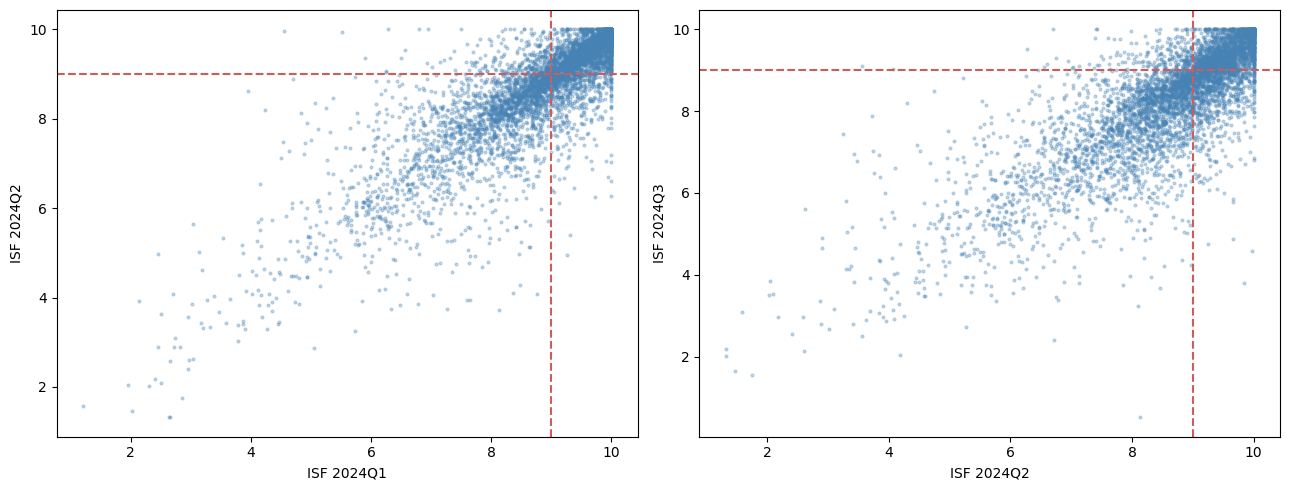

correlação Q1 x Q2: 0.844
correlação Q2 x Q3: 0.806


abaixo de 9 em Q3,False,True
abaixo de 9 em Q2,,
False,1829,886
True,239,2616


In [13]:
largo = isf.unstack('ds_quadrimestre')

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for eixo, (t, t1) in zip(eixos, [('2024Q1', '2024Q2'), ('2024Q2', '2024Q3')]):
    eixo.scatter(largo[t], largo[t1], s=4, alpha=0.3, color='steelblue')
    eixo.axvline(CORTE, color='indianred', ls='--')
    eixo.axhline(CORTE, color='indianred', ls='--')
    eixo.set_xlabel(f'ISF {t}')
    eixo.set_ylabel(f'ISF {t1}')
plt.tight_layout()
plt.show()

print('correlação Q1 x Q2:', round(largo['2024Q1'].corr(largo['2024Q2']), 3))
print('correlação Q2 x Q3:', round(largo['2024Q2'].corr(largo['2024Q3']), 3))
pd.crosstab(largo['2024Q2'] < CORTE, largo['2024Q3'] < CORTE, rownames=['abaixo de 9 em Q2'], colnames=['abaixo de 9 em Q3'])

In [14]:
populacao = df.groupby(chave)['populacao'].first().xs('2024Q1', level='ds_quadrimestre')
porte = pd.qcut(populacao, 4, labels=['1º quartil', '2º quartil', '3º quartil', '4º quartil'])
(largo['2024Q2'] - largo['2024Q1']).abs().groupby(porte, observed=True).mean().round(2).rename('variação média do ISF, Q1 para Q2')

populacao
1º quartil    0.62
2º quartil    0.46
3º quartil    0.40
4º quartil    0.34
Name: variação média do ISF, Q1 para Q2, dtype: float64

A correlação do ISF entre quadrimestres seguidos é de 0,84 (Q1 e Q2) e 0,81 (Q2 e Q3), e a maioria dos pontos fica perto da diagonal. Perto do corte, porém, muitos municípios mudam de lado: de Q2 para Q3, 886 municípios que tinham ISF 9 ou mais ficaram abaixo de 9, e 239 fizeram o caminho inverso. O baseline erra esses 1.125 casos.

A variação também depende do tamanho do município. No quartil de menor população, o ISF muda em média 0,62 ponto entre Q1 e Q2; no de maior população, 0,34.

### Distribuição do target

In [15]:
(largo < CORTE).mean().round(3)

ds_quadrimestre
2024Q1    0.471
2024Q2    0.513
2024Q3    0.629
dtype: float64

No treino (alvo em Q2), 51,3% dos municípios ficam abaixo de 9. No teste (alvo em Q3), 62,9%. O teste tem mais positivos que o treino, e por isso:

- a separação de validação é estratificada (`stratify=y`);
- a métrica principal é a balanced accuracy, que não depende da proporção entre as classes;
- também acompanhamos o recall da classe `abaixo_90`, porque deixar de prever uma queda é pior que um alarme falso, e a AUC, que não depende do limiar.

### Valores faltantes

In [16]:
print('ausentes na base:', df.isna().sum().sum())
print('linhas repetidas (município, quadrimestre, indicador):', df.duplicated(['ibge', 'ds_quadrimestre', 'indicador']).sum())
print('municípios por quadrimestre:', df.groupby('ds_quadrimestre')['ibge'].nunique().to_dict())
print('municípios nos três quadrimestres:', largo.dropna().shape[0])
largo[largo.isna().any(axis=1)]

ausentes na base: 0
linhas repetidas (município, quadrimestre, indicador): 0
municípios por quadrimestre: {'2024Q1': 5568, '2024Q2': 5568, '2024Q3': 5568}
municípios nos três quadrimestres: 5566


,ds_quadrimestre,2024Q1,2024Q2,2024Q3
ibge,uf,,,
150490,PA,NaN,NaN,7.461842
150570,PA,6.485417,NaN,NaN
352760,SP,NaN,6.199306,5.334028
354500,SP,5.881140,7.356469,NaN


Não há valores ausentes nem linhas duplicadas. Cada quadrimestre tem 5.568 dos 5.570 municípios, e quatro municípios (dois do Pará e dois de São Paulo) não aparecem nos três quadrimestres, provavelmente por não terem equipe válida em algum período. Na montagem dos pares de treino e teste usamos só os municípios presentes nos dois quadrimestres de cada par, sem imputação.

### Outliers e inconsistências

resultado diferente de numerador / denominador (mais de 1 ponto): 0
denominador zero: 7 | resultado nesses casos: [0.]
identificado acima de 3x o estimado: 923 | máximo: 1800
cadastro maior que a população: 70.6% | máximo: 2.25
resultado em 100%: {'ind1': 0.018, 'ind2': 0.104, 'ind3': 0.058, 'ind4': 0.0, 'ind5': 0.192, 'ind7': 0.0}
gestantes no denominador (mediana): resultado 0 ou 100: 12.0 | resto: 46.0
população (mediana): identificado acima de 3x: 2564.0 | todos: 11065.0


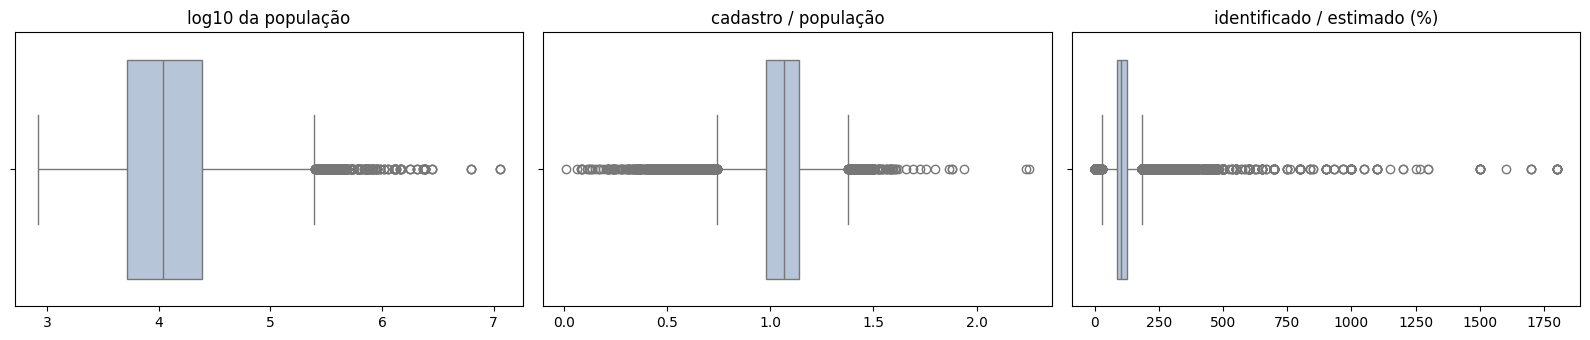

In [17]:
cadastro = df.groupby(chave)[['cadastro', 'populacao']].first()
cobertura = cadastro['cadastro'] / cadastro['populacao']
recalculado = (df['numerador'] / df['denominador_utilizador'] * 100).round()

print('resultado diferente de numerador / denominador (mais de 1 ponto):', (recalculado - df['vl_perc_quad']).abs().gt(1).sum())
print('denominador zero:', (df['denominador_utilizador'] == 0).sum(), '| resultado nesses casos:', df.loc[df['denominador_utilizador'] == 0, 'vl_perc_quad'].unique())
print('identificado acima de 3x o estimado:', (df['percentual'] > 300).sum(), '| máximo:', df['percentual'].max())
print('cadastro maior que a população:', f'{(cobertura > 1).mean():.1%}', '| máximo:', round(cobertura.max(), 2))
print('resultado em 100%:', df['vl_perc_quad'].eq(100).groupby(df['indicador']).mean().round(3).to_dict())

gestante = df[df['indicador'].isin(['ind1', 'ind2', 'ind3'])]
extremo = gestante['vl_perc_quad'].isin([0, 100])
print('gestantes no denominador (mediana): resultado 0 ou 100:', gestante.loc[extremo, 'denominador_utilizador'].median(), '| resto:', gestante.loc[~extremo, 'denominador_utilizador'].median())
print('população (mediana): identificado acima de 3x:', df.loc[df['percentual'] > 300, 'populacao'].median(), '| todos:', df['populacao'].median())

fig, eixos = plt.subplots(1, 3, figsize=(16, 3.5))
sns.boxplot(x=np.log10(cadastro['populacao']), ax=eixos[0], color='lightsteelblue')
sns.boxplot(x=cobertura, ax=eixos[1], color='lightsteelblue')
sns.boxplot(x=df['percentual'], ax=eixos[2], color='lightsteelblue')
for eixo, titulo in zip(eixos, ['log10 da população', 'cadastro / população', 'identificado / estimado (%)']):
    eixo.set_title(titulo)
    eixo.set_xlabel('')
plt.tight_layout()
plt.show()

- Em nenhuma linha `vl_perc_quad` difere de `numerador / denominador` em mais de um ponto.
- Sete linhas têm denominador zero e resultado 0. São municípios sem gestante ou criança identificada no período. Mantivemos assim porque é o valor que o Ministério usa no cálculo.
- Os resultados 0 e 100 nos indicadores da gestante vêm de municípios pequenos: mediana de 12 gestantes no denominador, contra 46 nos demais.
- A coluna `percentual` (identificado sobre estimado) chega a 1.800%, com 923 linhas acima de 300%. São municípios pequenos (mediana de 2.564 habitantes) em que a estimativa por base externa fica baixa. O valor só faz diferença abaixo de 85%, quando o cálculo passa a usar o denominador estimado, então a feature usa esse corte em vez do valor bruto.
- O cadastro é maior que a população em 70,6% dos registros, chegando a 2,25 vezes. A população é uma estimativa do IBGE e o cadastro inclui pessoas de outros municípios e cadastros duplicados. Mantivemos e usamos a razão como feature.
- A população vai de 833 habitantes a 11,4 milhões. Os pontos extremos do boxplot são capitais e cidades grandes. Ficam na base, e o modelo usa o log da população.

### Resumo da EDA

1. Dá para recalcular o ISF de cada município com as metas e os pesos oficiais, e a função confere com o exemplo do manual.
2. Citopatológico, vacinação e diabetes são os indicadores que a maioria dos municípios não atinge, e por isso são os que mais reduzem o ISF.
3. O ISF muda pouco de um quadrimestre para o outro (correlação de 0,81 a 0,84), mas caiu ao longo de 2024, principalmente em Q3.
4. Municípios pequenos variam mais, porque têm denominadores pequenos.
5. A base não tem ausentes nem duplicados. As inconsistências encontradas vêm da forma como os dados são produzidos, e não de erro de digitação.

## 4. Pré-processamento

| Etapa | Decisão | Motivo |
| --- | --- | --- |
| Visão de equipe | só `validas` | é a usada no pagamento |
| Indicador 6 | ISF parcial, soma de pesos 8 | não está na base aberta |
| Valores faltantes | nenhum tratamento | não há ausentes; os 4 municípios incompletos saem só do par em que faltam |
| Duplicados | nenhum tratamento | não há linhas repetidas |
| Denominador zero | mantido, com resultado 0 | é o resultado oficial |
| Outliers | mantidos | capitais, municípios pequenos e cadastro acima da população são casos reais, e os modelos de árvore não dependem de escala |
| Colunas descartadas | `municipio`, `nu_competencia`, `dt_criacao_registro`, `visao_equipe`, numeradores e bases externas | repetem outra coluna ou foram usadas para criar features |
| Formato | uma linha por município e quadrimestre, um indicador por coluna | a previsão é por município |
| Treino e teste | temporal: Q1 → Q2 para treino, Q2 → Q3 para teste | é o uso real, prever um quadrimestre que ainda não aconteceu |
| Encoding | `uf` em one-hot | ver a parte de encoding |
| Normalização | não aplicada | todos os modelos são baseados em árvore |

### Feature engineering

Criamos oito atributos a partir do que vimos na EDA:

- `isf`: o ISF atual, calculado pela regra. Uma árvore precisaria de muitos cortes para reconstruir essa soma ponderada com limite em 10.
- `metas_batidas`: quantas das seis metas o município atinge.
- `folga_min`: o menor valor de `resultado / meta - 1` entre os indicadores. Quando é negativo, indica quanto falta no pior indicador.
- `log_gestantes` e `log_diabeticos`: log do tamanho dos denominadores, para captar a instabilidade dos municípios pequenos.
- `n_estimado`: em quantos indicadores o cálculo usou o denominador estimado (identificado abaixo de 85% do estimado), o que indica registro incompleto.
- `cobertura`: cadastro dividido pela população.
- `log_pop`: log da população.

In [18]:
den = df.pivot_table(index=chave, columns='indicador', values='denominador_utilizador')
usa_estimado = df.assign(est=df['percentual'] < 85).groupby(chave)['est'].sum()

mun = res.copy()
mun['isf'] = isf
mun['metas_batidas'] = (res >= METAS).sum(axis=1)
mun['folga_min'] = (res / METAS - 1).min(axis=1)
mun['log_gestantes'] = np.log1p(den['ind1'])
mun['log_diabeticos'] = np.log1p(den['ind7'])
mun['n_estimado'] = usa_estimado
mun['cobertura'] = cobertura
mun['log_pop'] = np.log(cadastro['populacao'])
mun = mun.reset_index()

In [19]:
def montar(t, t1):
    atual = mun[mun['ds_quadrimestre'] == t].set_index('ibge')
    seguinte = mun[mun['ds_quadrimestre'] == t1].set_index('ibge')
    comuns = atual.index.intersection(seguinte.index)
    X = atual.loc[comuns].drop(columns='ds_quadrimestre')
    y = (seguinte.loc[comuns, 'isf'] < CORTE).astype(int).rename('abaixo_90')
    return X, y

X_treino, y_treino = montar('2024Q1', '2024Q2')
X_teste, y_teste = montar('2024Q2', '2024Q3')
print('treino (Q1 -> Q2):', X_treino.shape, '| teste (Q2 -> Q3):', X_teste.shape)

treino (Q1 -> Q2): (5567, 15) | teste (Q2 -> Q3): (5567, 15)


### Análise das novas features

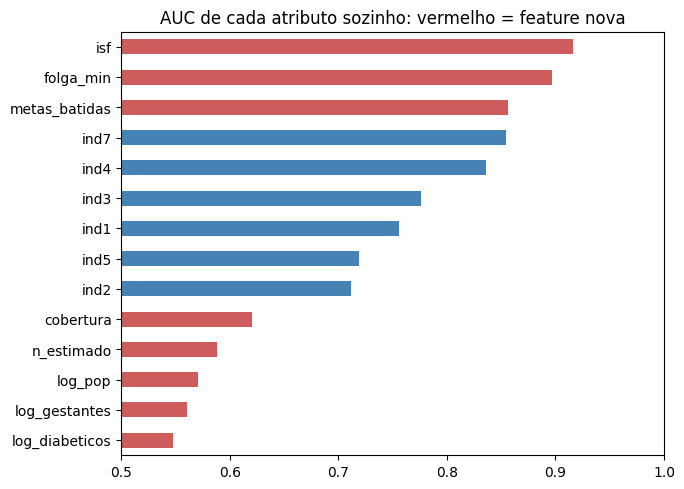

,ind1,ind2,ind3,ind4,ind5,ind7,isf,metas_batidas,folga_min,log_gestantes,log_diabeticos,n_estimado,cobertura,log_pop
abaixo_90,,,,,,,,,,,,,,
0,72.0,90.0,84.0,43.0,96.0,48.0,9.67,5.0,-0.18,3.66,6.92,0.0,1.10,9.24
1,54.0,73.0,60.0,27.0,88.0,22.0,8.33,3.0,-0.62,3.93,7.07,1.0,1.05,9.48


In [20]:
novas = ['isf', 'metas_batidas', 'folga_min', 'log_gestantes', 'log_diabeticos', 'n_estimado', 'cobertura', 'log_pop']
numericas = list(METAS.index) + novas

auc = pd.Series({c: roc_auc_score(y_treino, X_treino[c]) for c in numericas})
separacao = (auc - 0.5).abs().add(0.5).sort_values()
cores = ['indianred' if c in novas else 'steelblue' for c in separacao.index]
separacao.plot.barh(figsize=(7, 5.5), color=cores, xlim=(0.5, 1))
plt.title('AUC de cada atributo sozinho: vermelho = feature nova')
plt.show()

pd.concat([X_treino[numericas], y_treino], axis=1).groupby('abaixo_90').median().round(2)

Sozinho, `isf` tem AUC de 0,917, `folga_min` tem 0,897 e `metas_batidas` tem 0,856. O melhor indicador individual é diabetes, com 0,854, seguido do citopatológico, com 0,836. Os municípios que ficam abaixo de 9 no quadrimestre seguinte têm mediana de 22% em diabetes, contra 48% dos que ficam acima, e mediana de `folga_min` de -0,62, contra -0,18.

As features de porte e de registro separam pouco sozinhas (AUC de 0,55 a 0,62). Elas indicam quanto o ISF pode variar, e não se ele é alto ou baixo, então esperávamos que ajudassem só em combinação com o ISF.

### Encoding

- `uf` é nominal, com 27 valores, e a proporção do target varia bastante entre os estados. Usamos one-hot, que gera 27 colunas.
- `ibge` é só um identificador e vira índice.
- Não padronizamos nada, porque todos os modelos são baseados em árvore.
- O one-hot é feito separadamente em treino e teste. O `assert` confere que as colunas são as mesmas nos dois.

In [21]:
X_treino = pd.get_dummies(X_treino, columns=['uf'], dtype=int)
X_teste = pd.get_dummies(X_teste, columns=['uf'], dtype=int)
assert list(X_treino.columns) == list(X_teste.columns)
print('treino:', X_treino.shape, '| teste:', X_teste.shape)

treino: (5567, 41) | teste: (5567, 41)


## 5. Planejamento

### Algoritmos

Testamos quatro algoritmos baseados em árvore e um ensemble. Escolhemos árvores porque os dados são tabulares, misturam escalas muito diferentes (população de 833 a 11 milhões, percentuais, contagens) e têm relações não lineares, como a nota que para de crescer quando atinge a meta.

| Modelo | Tipo | Motivo da escolha |
| --- | --- | --- |
| Random Forest | bagging | ensemble de árvores que funciona bem com pouco ajuste de hiperparâmetros |
| XGBoost | boosting | costuma ter o melhor desempenho em dados tabulares e tem regularização L1 e L2 |
| LightGBM | boosting | parecido com o XGBoost, com crescimento por folha e treino mais rápido |
| CatBoost | boosting | usa boosting ordenado, que tende a sobreajustar menos com os parâmetros padrão |
| Ensemble | média das probabilidades de XGBoost, LightGBM e CatBoost | verificar se combinar os três melhora o resultado |

Todos são comparados com o baseline que repete o resultado atual.

### Métricas

| Métrica | Uso | Motivo |
| --- | --- | --- |
| Balanced accuracy | principal, usada para escolher o modelo | média do recall das duas classes; não muda com a proporção do target, que é de 51% no treino e 63% no teste |
| Recall de `abaixo_90` | acompanhamento | um município que vai cair e não é previsto perde incentivo sem aviso |
| AUC | acompanhamento | avalia a ordenação das probabilidades, independente do limiar |
| Precisão e F1 de `abaixo_90` | apoio | mostram quantos alarmes falsos vêm junto com o recall |

Definimos três critérios de sucesso antes de avaliar no teste:

1. Balanced accuracy e recall no teste maiores que os do baseline.
2. Entre os municípios com ISF 9 ou mais, precisão dos alertas de queda maior que a proporção desse grupo que de fato cai.
3. Desvio padrão da balanced accuracy menor que 0,01 entre as dobras da validação cruzada.

### Protocolo de avaliação

A comparação entre modelos, o ajuste de hiperparâmetros e a escolha do limiar usam só o treino (pares Q1 → Q2), com validação cruzada estratificada de 5 dobras. O teste (pares Q2 → Q3) é usado uma única vez, depois da escolha do modelo final.

Função que calcula as métricas para um conjunto de previsões. É usada tanto na validação cruzada quanto no teste.

In [22]:
def metricas(y, score, previsto):
    """As métricas de sucesso definidas no planejamento, para um conjunto de previsões."""
    return {
        'balanced accuracy': balanced_accuracy_score(y, previsto),
        'recall abaixo_90': recall_score(y, previsto),
        'precisão abaixo_90': precision_score(y, previsto, zero_division=0),
        'F1 abaixo_90': f1_score(y, previsto),
        'AUC': roc_auc_score(y, score),
    }

PRINCIPAIS = ['balanced accuracy', 'recall abaixo_90', 'AUC']

## 6. Modelagem

### 6.1 Número de árvores

Para os três modelos de boosting, definimos o número de árvores com early stopping. Separamos 20% do treino para validação (estratificado), treinamos com até 3.000 árvores e paramos quando o logloss da validação não melhora por 100 rodadas. O número de árvores da melhor rodada fica fixo no resto do caderno.

In [23]:
X_train, X_val, y_train, y_val = train_test_split(
    X_treino, y_treino, test_size=0.2, stratify=y_treino, random_state=RANDOM_STATE
)

In [24]:
PARAMS_XGB = dict(learning_rate=0.03, max_depth=4, min_child_weight=5, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=1, tree_method='hist',
                  random_state=RANDOM_STATE, n_jobs=-1)
PARAMS_LGBM = dict(learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8,
                   subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)
PARAMS_CAT = dict(learning_rate=0.03, depth=5, random_seed=RANDOM_STATE, verbose=False,
                  allow_writing_files=False)

xgb_es = XGBClassifier(n_estimators=3000, eval_metric='logloss', early_stopping_rounds=100, **PARAMS_XGB)
xgb_es.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

lgbm_es = LGBMClassifier(n_estimators=3000, **PARAMS_LGBM)
lgbm_es.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lightgbm.early_stopping(100, verbose=False)])

cat_es = CatBoostClassifier(iterations=3000, eval_metric='Logloss', od_type='Iter', od_wait=100, **PARAMS_CAT)
cat_es.fit(X_train, y_train, eval_set=(X_val, y_val))

ARVORES = {
    'XGBoost': xgb_es.best_iteration + 1,
    'LightGBM': lgbm_es.best_iteration_,
    'CatBoost': cat_es.get_best_iteration() + 1,
}
pd.DataFrame({
    'árvores': ARVORES,
    'logloss na validação': {
        'XGBoost': xgb_es.best_score,
        'LightGBM': lgbm_es.best_score_['valid_0']['binary_logloss'],
        'CatBoost': cat_es.get_best_score()['validation']['Logloss'],
    },
}).round(4)

,árvores,logloss na validação
XGBoost,321,0.3087
LightGBM,190,0.3108
CatBoost,551,0.3058


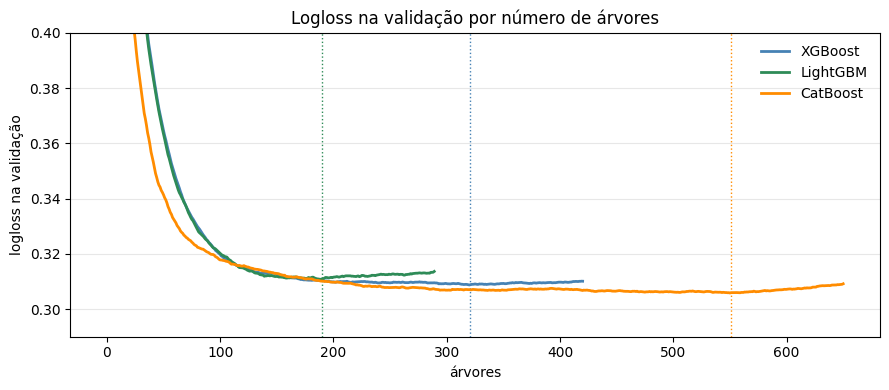

In [25]:
curvas = {
    'XGBoost': xgb_es.evals_result()['validation_0']['logloss'],
    'LightGBM': lgbm_es.evals_result_['valid_0']['binary_logloss'],
    'CatBoost': cat_es.get_evals_result()['validation']['Logloss'],
}
fig, ax = plt.subplots(figsize=(9, 4))
for (nome, curva), cor in zip(curvas.items(), ['steelblue', 'seagreen', 'darkorange']):
    ax.plot(curva, lw=2, color=cor, label=nome)
    ax.axvline(ARVORES[nome], color=cor, ls=':', lw=1)
ax.set_ylim(0.29, 0.40)
ax.set_xlabel('árvores')
ax.set_ylabel('logloss na validação')
ax.set_title('Logloss na validação por número de árvores')
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Os três modelos chegam a um logloss parecido na validação (entre 0,306 e 0,311), com números de árvores bem diferentes: 190 no LightGBM, 321 no XGBoost e 551 no CatBoost. Depois do mínimo, o logloss volta a subir aos poucos, o que indica sobreajuste.

Os outros hiperparâmetros (profundidade 4 ou 5, amostragem de 80% das linhas e das colunas) foram escolhidos de forma conservadora para um treino de cerca de 4.500 linhas. Na seção 7.3 testamos se ajustá-los melhora o resultado.

### 6.2 Modelos

A função `candidatos()` cria os modelos sem treino, para que cada dobra da validação cruzada comece de um modelo novo. O ensemble foi implementado como um classificador compatível com o scikit-learn, e assim passa pela mesma validação cruzada e pela mesma importância por permutação dos outros modelos.

In [26]:
class MediaDeModelos(ClassifierMixin, BaseEstimator):
    """Ensemble por média simples das probabilidades de vários classificadores."""

    def __init__(self, modelos):
        self.modelos = modelos

    def fit(self, X, y):
        self.modelos_ = [clone(m).fit(X, y) for m in self.modelos]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.modelos_], axis=0)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)


def candidatos():
    """Modelos novos, sem treino, com os hiperparâmetros do planejamento."""
    xgb = XGBClassifier(n_estimators=ARVORES['XGBoost'], **PARAMS_XGB)
    lgbm = LGBMClassifier(n_estimators=ARVORES['LightGBM'], **PARAMS_LGBM)
    cat = CatBoostClassifier(iterations=ARVORES['CatBoost'], **PARAMS_CAT)
    return {
        'Random Forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features='sqrt',
                                                n_jobs=-1, random_state=RANDOM_STATE),
        'XGBoost': xgb,
        'LightGBM': lgbm,
        'CatBoost': cat,
        'ensemble': MediaDeModelos([xgb, lgbm, cat]),
    }

list(candidatos())

['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'ensemble']

## 7. Experimentos

### 7.1 Comparação inicial

Cada modelo é treinado em 4 dobras e avaliado na quinta, cinco vezes. O baseline é avaliado nas mesmas dobras. Guardamos também a probabilidade prevista para cada município quando ele estava na dobra de validação (`oof`), que usamos nas análises seguintes.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof = pd.DataFrame(index=X_treino.index, dtype=float)   # probabilidade fora da dobra
linhas = []
for dobra, (i_tr, i_va) in enumerate(cv.split(X_treino, y_treino)):
    X_tr, X_va = X_treino.iloc[i_tr], X_treino.iloc[i_va]
    y_tr, y_va = y_treino.iloc[i_tr], y_treino.iloc[i_va]

    isf_va = X_va['isf']
    oof.loc[X_va.index, 'baseline'] = CORTE - isf_va
    linhas.append({'modelo': 'baseline', 'dobra': dobra, 'segundos': 0.0,
                   **metricas(y_va, CORTE - isf_va, isf_va < CORTE)})

    for nome, modelo in candidatos().items():
        inicio = time.perf_counter()
        modelo.fit(X_tr, y_tr)
        segundos = time.perf_counter() - inicio
        p = modelo.predict_proba(X_va)[:, 1]
        oof.loc[X_va.index, nome] = p
        linhas.append({'modelo': nome, 'dobra': dobra, 'segundos': segundos, **metricas(y_va, p, p > 0.5)})

cv_res = pd.DataFrame(linhas)
print(len(cv_res), 'avaliações:', cv_res['modelo'].nunique(), 'modelos x 5 dobras')

30 avaliações: 6 modelos x 5 dobras


In [28]:
media = cv_res.groupby('modelo').mean(numeric_only=True).drop(columns='dobra')
desvio = cv_res.groupby('modelo').std(numeric_only=True).drop(columns='dobra')
ordem = media['balanced accuracy'].sort_values(ascending=False).index

tabela_cv = pd.DataFrame(index=ordem)
for m in ['balanced accuracy', 'recall abaixo_90', 'precisão abaixo_90', 'F1 abaixo_90', 'AUC']:
    tabela_cv[m] = [f'{media.loc[i, m]:.3f} ± {desvio.loc[i, m]:.3f}' for i in ordem]
tabela_cv['treino por dobra (s)'] = media.loc[ordem, 'segundos'].round(2)
tabela_cv

,balanced accuracy,recall abaixo_90,precisão abaixo_90,F1 abaixo_90,AUC,treino por dobra (s)
modelo,,,,,,
XGBoost,0.864 ± 0.003,0.843 ± 0.015,0.885 ± 0.011,0.863 ± 0.004,0.936 ± 0.010,0.46
ensemble,0.863 ± 0.002,0.840 ± 0.019,0.886 ± 0.013,0.862 ± 0.004,0.936 ± 0.010,3.21
LightGBM,0.862 ± 0.004,0.838 ± 0.021,0.887 ± 0.011,0.861 ± 0.006,0.935 ± 0.010,0.18
CatBoost,0.861 ± 0.008,0.843 ± 0.017,0.881 ± 0.014,0.861 ± 0.009,0.935 ± 0.009,2.55
Random Forest,0.858 ± 0.006,0.839 ± 0.018,0.878 ± 0.009,0.858 ± 0.007,0.934 ± 0.010,1.56
baseline,0.850 ± 0.008,0.813 ± 0.016,0.884 ± 0.007,0.847 ± 0.010,0.917 ± 0.011,0.00


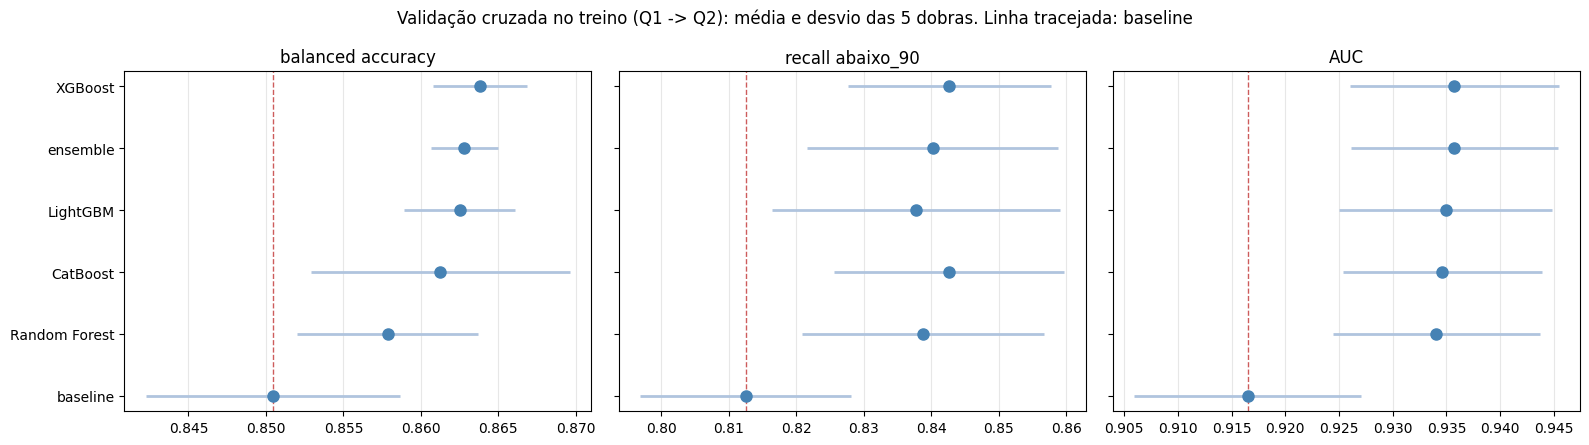

In [29]:
no_grafico = ordem[::-1]
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for eixo, m in zip(eixos, PRINCIPAIS):
    pontos = cv_res.pivot(index='dobra', columns='modelo', values=m)[no_grafico]
    eixo.errorbar(pontos.mean(), range(len(no_grafico)), xerr=pontos.std(), fmt='o', ms=8,
                  color='steelblue', ecolor='lightsteelblue', elinewidth=2, capsize=0)
    eixo.axvline(pontos['baseline'].mean(), color='indianred', ls='--', lw=1)
    eixo.set_yticks(range(len(no_grafico)), no_grafico)
    eixo.set_title(m)
    eixo.grid(axis='x', alpha=0.3)
fig.suptitle('Validação cruzada no treino (Q1 -> Q2): média e desvio das 5 dobras. Linha tracejada: baseline')
plt.tight_layout()
plt.show()

Todos os modelos ficaram acima do baseline (0,850), com balanced accuracy entre 0,858 e 0,864. Os três boosting e o ensemble ficaram entre 0,861 e 0,864, com diferenças menores que o desvio entre as dobras, então na prática empatam. O XGBoost teve a maior média e o menor desvio entre os modelos individuais (0,003). O Random Forest ficou um pouco abaixo dos boosting.

A diferença para o baseline existe, mas é pequena: cerca de 0,013 em balanced accuracy e 0,019 em AUC. Isso confirma o que vimos na EDA, que o ISF atual já explica a maior parte do ISF seguinte.

Em tempo de treino, LightGBM e XGBoost levam menos de um segundo por dobra. O ensemble leva a soma dos três e não teve resultado melhor.

### 7.2 Análise detalhada

Curva ROC com as probabilidades fora da dobra de todos os municípios do treino:

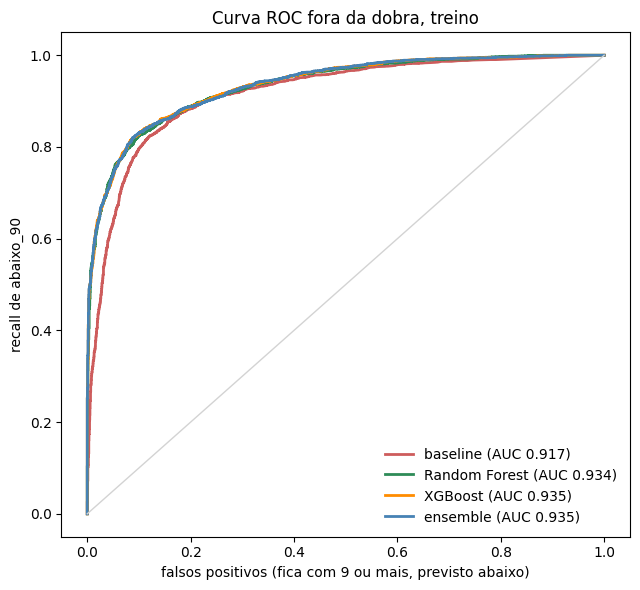

In [30]:
fig, ax = plt.subplots(figsize=(6.5, 6))
mostrar = ['baseline', 'Random Forest', 'XGBoost', 'ensemble']
cores = ['indianred', 'seagreen', 'darkorange', 'steelblue']
for nome, cor in zip(mostrar, cores):
    fpr, tpr, _ = roc_curve(y_treino, oof[nome])
    ax.plot(fpr, tpr, lw=2, color=cor, label=f'{nome} (AUC {roc_auc_score(y_treino, oof[nome]):.3f})')
ax.plot([0, 1], [0, 1], color='lightgray', lw=1)
ax.set_xlabel('falsos positivos (fica com 9 ou mais, previsto abaixo)')
ax.set_ylabel('recall de abaixo_90')
ax.set_title('Curva ROC fora da dobra, treino')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

As curvas dos modelos praticamente se sobrepõem. O baseline fica abaixo deles na parte esquerda do gráfico, até uma taxa de falsos positivos de cerca de 20%, e se junta às outras curvas a partir de 30%. A parte esquerda corresponde a selecionar só os municípios de maior risco, que é como o modelo seria usado na prática.

Diferença de balanced accuracy de cada modelo para o baseline, em cada dobra:

In [31]:
# Diferença de balanced accuracy de cada modelo para o baseline, por dobra
ganho = {}
base_ba = cv_res[cv_res['modelo'] == 'baseline'].set_index('dobra')['balanced accuracy']
for nome in ordem.drop('baseline'):
    ba = cv_res[cv_res['modelo'] == nome].set_index('dobra')['balanced accuracy']
    ganho[nome] = ba - base_ba
ganho = pd.DataFrame(ganho).T
ganho['média'] = ganho.mean(axis=1)
ganho['dobras em que vence'] = (ganho.drop(columns='média') > 0).sum(axis=1)
ganho.round(3)

dobra,0,1,2,3,4,média,dobras em que vence
XGBoost,0.021,0.011,0.017,0.006,0.012,0.013,5
ensemble,0.020,0.013,0.019,0.002,0.009,0.012,5
LightGBM,0.021,0.015,0.014,0.007,0.004,0.012,5
CatBoost,0.009,0.010,0.019,-0.001,0.017,0.011,4
Random Forest,0.009,0.013,0.013,-0.002,0.005,0.007,4


XGBoost, LightGBM e o ensemble superam o baseline nas cinco dobras. CatBoost e Random Forest ficam abaixo dele na dobra 3. O XGBoost tem o maior ganho médio (0,013), e o seu menor ganho em uma dobra ainda é positivo (0,006).

Em seguida olhamos só os municípios com ISF 9 ou mais no quadrimestre atual. O baseline sempre prevê que esses municípios continuam acima de 9, então qualquer acerto de queda nesse grupo vem do modelo.

In [32]:
# Municípios com ISF >= 9 em Q1: quantos caem em Q2 e quantos o modelo acerta
acima_tr = X_treino['isf'] >= CORTE
y_acima = y_treino[acima_tr]
print(f'municípios com ISF >= 9 em Q1: {acima_tr.sum()} | caíram em Q2: {y_acima.sum()} ({y_acima.mean():.1%})')

linhas = []
for nome in ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'ensemble']:
    p = oof.loc[acima_tr, nome]
    alerta = p > 0.5
    linhas.append({
        'modelo': nome,
        'alertas': int(alerta.sum()),
        'acertos': int((alerta & (y_acima == 1)).sum()),
        'precisão dos alertas': precision_score(y_acima, alerta, zero_division=0),
        'recall das quedas': recall_score(y_acima, alerta),
        'AUC dentro do grupo': roc_auc_score(y_acima, p),
    })
pd.DataFrame(linhas).set_index('modelo').round(3)

municípios com ISF >= 9 em Q1: 2945 | caíram em Q2: 535 (18.2%)


,alertas,acertos,precisão dos alertas,recall das quedas,AUC dentro do grupo
modelo,,,,,
Random Forest,187,103,0.551,0.193,0.789
XGBoost,217,128,0.590,0.239,0.797
LightGBM,197,116,0.589,0.217,0.794
CatBoost,225,127,0.564,0.237,0.794
ensemble,206,121,0.587,0.226,0.797


No treino, 535 dos 2.945 municípios com ISF 9 ou mais (18,2%) ficaram abaixo de 9 no quadrimestre seguinte. Entre os municípios que os modelos marcaram como queda, a proporção que de fato caiu ficou entre 55% e 59%, cerca de três vezes esses 18,2%. O XGBoost teve a maior precisão (0,590) e a maior AUC dentro do grupo (0,797, igual à do ensemble).

O recall das quedas é baixo em todos os modelos (19% a 24%): a maior parte dos municípios que caem não mostrava sinal disso no quadrimestre anterior.

Balanced accuracy por quartil de população, com as probabilidades fora da dobra:

In [33]:
porte_tr = pd.qcut(X_treino['log_pop'], 4, labels=['1º quartil', '2º quartil', '3º quartil', '4º quartil'])
por_porte = {}
for nome in ['baseline', 'Random Forest', 'XGBoost', 'ensemble']:
    previsto = (X_treino['isf'] < CORTE) if nome == 'baseline' else (oof[nome] > 0.5)
    por_porte[nome] = pd.Series({
        q: balanced_accuracy_score(y_treino[porte_tr == q], previsto[porte_tr == q])
        for q in porte_tr.cat.categories
    })
pd.DataFrame(por_porte).round(3).rename_axis('porte (população)')

,baseline,Random Forest,XGBoost,ensemble
porte (população),,,,
1º quartil,0.791,0.810,0.812,0.810
2º quartil,0.840,0.851,0.860,0.855
3º quartil,0.857,0.868,0.874,0.873
4º quartil,0.902,0.879,0.887,0.893


Os modelos e o baseline erram mais nos municípios pequenos. O baseline vai de 0,902 no maior quartil para 0,791 no menor, e os modelos ficam acima dele nos três primeiros quartis. No quartil de maior população nenhum modelo supera o baseline (Random Forest com 0,879 e XGBoost com 0,887, contra 0,902). Nesses municípios o ISF quase não varia, e repetir o valor atual já funciona bem.

### 7.3 Ajuste de hiperparâmetros

Como o XGBoost teve o melhor resultado, testamos 18 combinações de profundidade máxima, peso mínimo por folha e regularização L2, com a mesma validação cruzada. A taxa de aprendizado e o número de árvores continuam os do early stopping.

In [34]:
# Grade de hiperparâmetros do XGBoost. Taxa de aprendizado e número de árvores ficam os do early stopping.
grade = GridSearchCV(
    XGBClassifier(n_estimators=ARVORES['XGBoost'], **PARAMS_XGB),
    param_grid={
        'max_depth': [3, 4, 6],
        'min_child_weight': [1, 5, 10],
        'reg_lambda': [1, 10],
    },
    scoring='balanced_accuracy',
    cv=cv,
    n_jobs=1,
)
grade.fit(X_treino, y_treino)

resultado_grade = (
    pd.DataFrame(grade.cv_results_['params'])
    .assign(media=grade.cv_results_['mean_test_score'], desvio=grade.cv_results_['std_test_score'])
    .sort_values('media', ascending=False)
    .reset_index(drop=True)
)
print('configuração do planejamento (max_depth=4, min_child_weight=5, reg_lambda=1):',
      round(resultado_grade.query('max_depth == 4 and min_child_weight == 5 and reg_lambda == 1')['media'].iloc[0], 4))
resultado_grade.round(4).head(8)

configuração do planejamento (max_depth=4, min_child_weight=5, reg_lambda=1): 0.8638


,max_depth,min_child_weight,reg_lambda,media,desvio
0,3,10,1,0.8663,0.0060
1,4,1,10,0.8646,0.0029
2,3,1,1,0.8642,0.0020
3,3,1,10,0.8642,0.0033
4,3,5,10,0.8642,0.0043
5,4,10,1,0.8642,0.0037
6,3,5,1,0.8640,0.0028
7,4,5,1,0.8638,0.0027


A melhor combinação (`max_depth=3`, `min_child_weight=10`, `reg_lambda=1`) chegou a 0,8663, contra 0,8638 da configuração inicial. A diferença de 0,0025 é menor que o desvio entre dobras dessa combinação (0,006), que é o dobro do desvio da configuração inicial. As oito melhores combinações ficam todas num intervalo de 0,003.

Mantivemos a configuração inicial, porque o ganho está dentro da variação entre dobras e ela é mais estável.

### 7.4 Limiar de decisão

Por padrão, o modelo prevê `abaixo_90 = 1` quando a probabilidade passa de 0,5. Testamos outros limiares com as probabilidades fora da dobra do XGBoost, ainda só no treino.

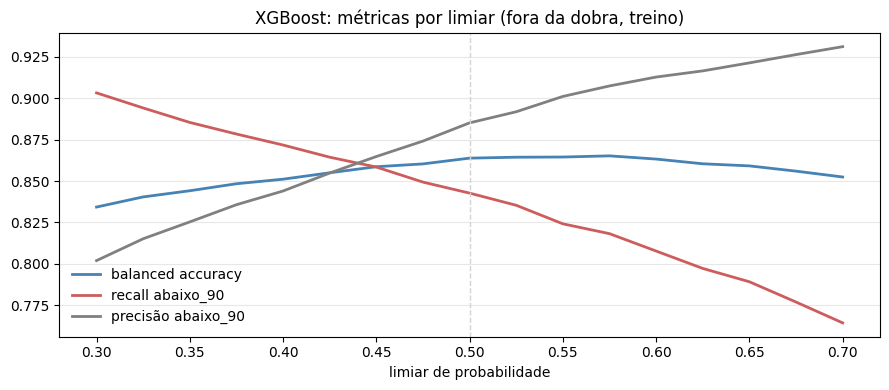

limiar com maior balanced accuracy no treino: 0.575


,balanced accuracy,recall abaixo_90,precisão abaixo_90
limiar,,,
0.40,0.851,0.872,0.844
0.45,0.859,0.858,0.865
0.50,0.864,0.843,0.885
0.55,0.865,0.824,0.901
0.60,0.863,0.808,0.913


In [35]:
limiares = np.round(np.arange(0.30, 0.71, 0.025), 3)
varredura = pd.DataFrame([
    {'limiar': t, **metricas(y_treino, oof['XGBoost'], oof['XGBoost'] > t)} for t in limiares
]).set_index('limiar')

fig, ax = plt.subplots(figsize=(9, 4))
for m, cor in [('balanced accuracy', 'steelblue'), ('recall abaixo_90', 'indianred'), ('precisão abaixo_90', 'gray')]:
    ax.plot(varredura.index, varredura[m], lw=2, color=cor, label=m)
ax.axvline(0.5, color='lightgray', ls='--', lw=1)
ax.set_xlabel('limiar de probabilidade')
ax.set_title('XGBoost: métricas por limiar (fora da dobra, treino)')
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print('limiar com maior balanced accuracy no treino:', varredura['balanced accuracy'].idxmax())
varredura.loc[[0.4, 0.45, 0.5, 0.55, 0.6], ['balanced accuracy', 'recall abaixo_90', 'precisão abaixo_90']].round(3)

A balanced accuracy quase não muda entre 0,45 e 0,60. O melhor valor no treino foi com limiar 0,575 (0,865), contra 0,864 com 0,5, então mantivemos 0,5.

Mudar o limiar serve mais para trocar precisão por recall: com 0,45, o recall sobe de 0,843 para 0,858 e a precisão cai cerca de 2 pontos. Se o objetivo for deixar passar menos quedas, vale usar um limiar menor.

## 8. Avaliação no teste

Agora treinamos todos os modelos com o treino completo (Q1 → Q2) e avaliamos no teste (Q2 → Q3).

In [36]:
modelos = candidatos()
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)

p_teste = pd.DataFrame({nome: m.predict_proba(X_teste)[:, 1] for nome, m in modelos.items()}, index=X_teste.index)

resultado_teste = {'baseline': metricas(y_teste, CORTE - X_teste['isf'], X_teste['isf'] < CORTE)}
for nome in modelos:
    resultado_teste[nome] = metricas(y_teste, p_teste[nome], p_teste[nome] > 0.5)
resultado_teste = pd.DataFrame(resultado_teste).T.loc[ordem]
resultado_teste.round(3)

,balanced accuracy,recall abaixo_90,precisão abaixo_90,F1 abaixo_90,AUC
modelo,,,,,
XGBoost,0.821,0.767,0.911,0.833,0.900
ensemble,0.820,0.765,0.912,0.832,0.901
LightGBM,0.820,0.765,0.912,0.832,0.902
CatBoost,0.821,0.766,0.912,0.833,0.901
Random Forest,0.822,0.775,0.909,0.837,0.903
baseline,0.816,0.747,0.917,0.823,0.887


Todos os modelos superam o baseline no teste em balanced accuracy, recall e AUC. As diferenças entre os modelos ficaram ainda menores que na validação: Random Forest, XGBoost e CatBoost estão entre 0,820 e 0,822, com o Random Forest 0,001 à frente. Não trocamos o modelo por causa disso, porque a diferença é menor que o desvio da validação cruzada e a escolha foi feita antes de olhar o teste.

Resultado do XGBoost no teste: balanced accuracy de 0,821 (baseline: 0,816), recall de 0,767 (baseline: 0,747) e AUC de 0,900 (baseline: 0,887).

Comparação entre a validação cruzada e o teste:

In [37]:
pd.DataFrame({
    'BA validação cruzada': media.loc[ordem, 'balanced accuracy'],
    'BA teste': resultado_teste['balanced accuracy'],
    'AUC validação cruzada': media.loc[ordem, 'AUC'],
    'AUC teste': resultado_teste['AUC'],
}).round(3)

,BA validação cruzada,BA teste,AUC validação cruzada,AUC teste
modelo,,,,
XGBoost,0.864,0.821,0.936,0.900
ensemble,0.863,0.820,0.936,0.901
LightGBM,0.862,0.820,0.935,0.902
CatBoost,0.861,0.821,0.935,0.901
Random Forest,0.858,0.822,0.934,0.903
baseline,0.850,0.816,0.917,0.887


Todos os modelos pioram no teste, mas o baseline, que não é treinado, piora na mesma proporção (de 0,850 para 0,816) que o XGBoost (de 0,864 para 0,821). Por isso atribuímos a queda ao período, e não a sobreajuste. Em Q3 a fração de municípios abaixo de 9 subiu de 51% para 63%, e a mediana de quase todos os indicadores caiu. O modelo foi treinado numa transição com menos quedas e não tinha como antecipar essa piora a partir dos dados de Q2.

## 9. Modelo final

Escolhemos o **XGBoost** com a configuração inicial (321 árvores, taxa de aprendizado 0,03, profundidade 4, `min_child_weight=5`, amostragem de 80% das linhas e das colunas) e limiar 0,5.

Motivos:

- teve a maior balanced accuracy na validação cruzada (0,864), que é a métrica principal;
- teve o menor desvio entre os modelos individuais (0,003) e superou o baseline nas cinco dobras;
- teve a maior precisão (0,590) e a maior AUC (0,797) no grupo de municípios com ISF 9 ou mais;
- treina em menos de um segundo, enquanto o ensemble teve o mesmo resultado e exige treinar três modelos;
- o ajuste de hiperparâmetros e de limiar não trouxe ganho maior que a variação entre dobras.

O Random Forest ficou 0,001 à frente no teste, mas teve resultado pior na validação cruzada e perdeu para o baseline em uma dobra.

Critérios de sucesso:

| Critério | Resultado | Atingido |
| --- | --- | --- |
| Superar o baseline em balanced accuracy e recall no teste | 0,821 contra 0,816 e 0,767 contra 0,747 | sim, com margem pequena |
| Precisão dos alertas maior que a taxa de queda do grupo | 65,2% contra 32,6% | sim |
| Desvio da balanced accuracy menor que 0,01 | 0,003 | sim |

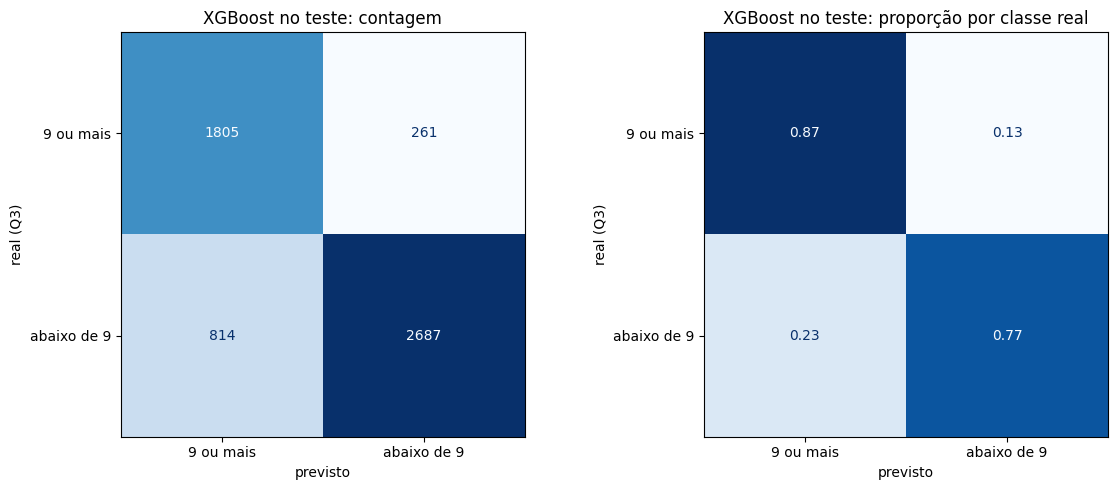

In [38]:
LIMIAR = 0.5
modelo_final = modelos['XGBoost']
p_final = p_teste['XGBoost']
previsto_final = (p_final > LIMIAR).astype(int)

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
for eixo, normalizar, fmt, titulo in [(eixos[0], None, 'd', 'contagem'), (eixos[1], 'true', '.2f', 'proporção por classe real')]:
    ConfusionMatrixDisplay.from_predictions(
        y_teste, previsto_final, display_labels=['9 ou mais', 'abaixo de 9'],
        normalize=normalizar, values_format=fmt, cmap='Blues', colorbar=False, ax=eixo,
    )
    eixo.set_title(f'XGBoost no teste: {titulo}')
    eixo.set_xlabel('previsto')
    eixo.set_ylabel('real (Q3)')
plt.tight_layout()
plt.show()

O modelo acerta 87% dos municípios que ficam com ISF 9 ou mais e 77% dos que ficam abaixo. São 814 falsos negativos (previstos com 9 ou mais que ficaram abaixo) e 261 falsos positivos. O número maior de falsos negativos é consequência da piora geral em Q3, discutida na seção 8.

Resultado no grupo com ISF 9 ou mais em Q2:

In [39]:
acima = X_teste['isf'] >= CORTE
quedas = y_teste[acima]
alerta = p_final[acima] > LIMIAR
print(f'ISF >= 9 em Q2: {acima.sum()} | caíram em Q3: {quedas.sum()} ({quedas.mean():.1%})')
print(f'alertas do modelo: {alerta.sum()} | acertos: {(alerta & (quedas == 1)).sum()} '
      f'| precisão: {precision_score(quedas, alerta):.1%} | recall: {recall_score(quedas, alerta):.1%}')
pd.crosstab(quedas, alerta, rownames=['abaixo de 9 em Q3'], colnames=['modelo prevê queda'])

ISF >= 9 em Q2: 2713 | caíram em Q3: 885 (32.6%)
alertas do modelo: 187 | acertos: 122 | precisão: 65.2% | recall: 13.8%


modelo prevê queda,False,True
abaixo de 9 em Q3,,
0,1763,65
1,763,122


Dos 2.713 municípios com ISF 9 ou mais em Q2, 885 (32,6%) ficaram abaixo de 9 em Q3. O baseline não prevê nenhum deles. O modelo marcou 187 como queda e acertou 122 (65%), cerca do dobro da taxa do grupo. Por outro lado, deixou de prever 763 quedas, o que dá um recall de 13,8% dentro do grupo.

Se o modelo for usado para ordenar os municípios por risco, sem limiar, a tabela abaixo mostra quantos dos N primeiros caíram de fato:

In [40]:
# Precisão entre os N municípios de maior probabilidade, no grupo com ISF >= 9 em Q2
risco = p_final[acima].sort_values(ascending=False)
taxa_base = quedas.mean()
pd.DataFrame({
    n: {'municípios': n, 'caíram de fato': int(quedas[risco.index[:n]].sum()),
        'precisão': quedas[risco.index[:n]].mean(), 'vezes a taxa do grupo': quedas[risco.index[:n]].mean() / taxa_base}
    for n in [50, 100, 200, 400]
}).T.round(2)

,municípios,caíram de fato,precisão,vezes a taxa do grupo
50,50.0,35.0,0.70,2.15
100,100.0,71.0,0.71,2.18
200,200.0,129.0,0.64,1.98
400,400.0,239.0,0.60,1.83


Dos 100 municípios com maior probabilidade, 71 caíram (2,2 vezes a taxa do grupo). Nos 400 primeiros, a precisão ainda é de 60%. Para uma equipe que só consegue acompanhar um número limitado de municípios, ordenar por probabilidade é a forma mais útil de usar o modelo.

## 10. Interpretação dos resultados

### 10.1 Importância das features

Usamos duas medidas. A importância por ganho do XGBoost mede quanto cada atributo melhorou as divisões durante o treino. A importância por permutação mede quanto a AUC no teste cai quando embaralhamos os valores de um atributo. A segunda é calculada em dados que o modelo não viu, mas subestima atributos correlacionados entre si: se dois atributos têm a mesma informação, embaralhar um deles quase não afeta o modelo.

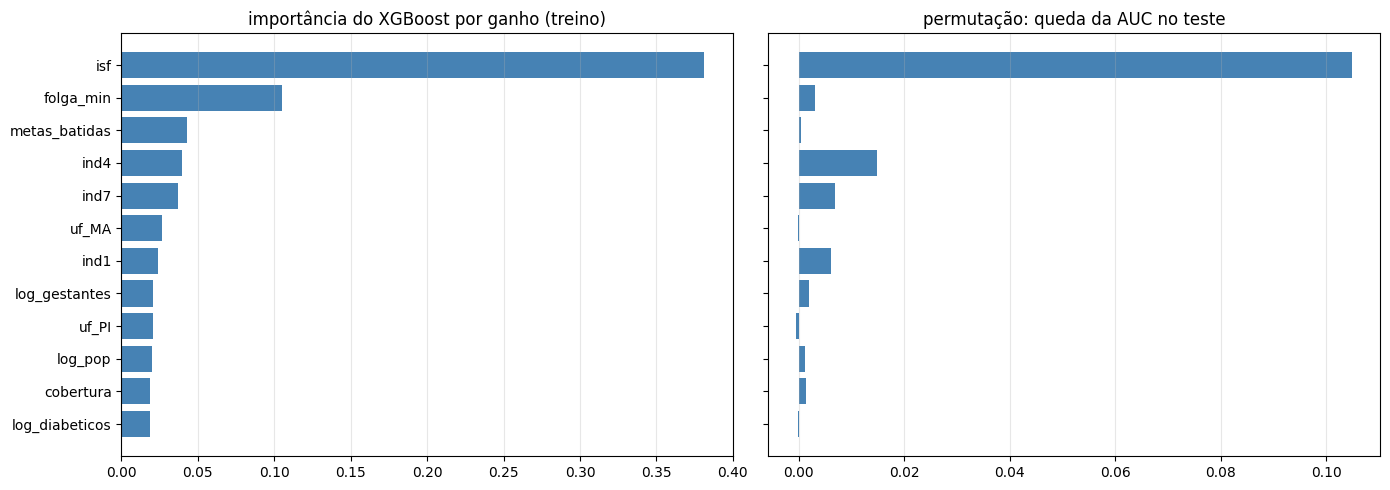

,XGBoost (ganho),permutação (AUC)
isf,0.381,0.105
folga_min,0.105,0.003
metas_batidas,0.043,0.000
ind4,0.040,0.015
ind7,0.037,0.007
uf_MA,0.027,-0.000
ind1,0.024,0.006
log_gestantes,0.021,0.002
uf_PI,0.020,-0.001
log_pop,0.020,0.001


In [41]:
nativa = pd.Series(modelo_final.feature_importances_, index=X_treino.columns)
perm = permutation_importance(modelo_final, X_teste, y_teste, scoring='roc_auc', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=1)
permutacao = pd.Series(perm.importances_mean, index=X_teste.columns)

top = nativa.sort_values(ascending=False).head(12).index
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
eixos[0].barh(top[::-1], nativa[top[::-1]], color='steelblue')
eixos[0].set_title('importância do XGBoost por ganho (treino)')
eixos[1].barh(top[::-1], permutacao[top[::-1]], color='steelblue')
eixos[1].set_title('permutação: queda da AUC no teste')
for eixo in eixos:
    eixo.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({'XGBoost (ganho)': nativa, 'permutação (AUC)': permutacao}).loc[top].round(3)

O `isf` atual é o atributo mais importante nas duas medidas: tem 38% do ganho, e embaralhá-lo reduz a AUC em 0,105. O modelo parte do ISF atual e faz ajustes a partir dele.

Depois do ISF, os indicadores que mais pesam na permutação são o citopatológico (ind4, 0,015) e o diabetes (ind7, 0,007), que são os dois com menor proporção de municípios na meta. Municípios com o mesmo ISF tendem a ir para lados diferentes de acordo com o desempenho nesses dois indicadores.

`folga_min` e `metas_batidas` aparecem bem no ganho, mas ficam perto de zero na permutação, porque têm informação parecida com a do ISF e dos indicadores. As colunas de UF (Maranhão e Piauí) também aparecem no ganho e não na permutação: o efeito de estado que o modelo aprendeu no treino não se repetiu no teste.

### 10.2 Exemplos de erros

Falsos negativos em que o modelo estava mais confiante (probabilidade de queda de 2%). Nas tabelas, as colunas de ISF e indicadores à esquerda são de Q2, e as três últimas são de Q3.

In [42]:
nomes = df.drop_duplicates('ibge').set_index('ibge')['municipio']
q3 = mun[mun['ds_quadrimestre'] == '2024Q3'].set_index('ibge')
colunas = ['isf', 'ind4', 'ind5', 'ind7', 'log_pop']

def exemplos(mascara, ascendente):
    sel = p_final[mascara].sort_values(ascending=ascendente).head(5).index
    tabela = X_teste.loc[sel, colunas].copy()
    tabela.insert(0, 'município', nomes[sel].values)
    tabela['população'] = np.exp(tabela.pop('log_pop')).round().astype(int)
    tabela['prob. abaixo de 9'] = p_final[sel]
    tabela['ISF em Q3'] = q3.loc[sel, 'isf']
    tabela['ind7 em Q3'] = q3.loc[sel, 'ind7']
    tabela['ind4 em Q3'] = q3.loc[sel, 'ind4']
    return tabela.round(2)

falso_negativo = (y_teste == 1) & (previsto_final == 0)
falso_positivo = (y_teste == 0) & (previsto_final == 1)
print('falsos negativos (previsto 9 ou mais, ficou abaixo):', falso_negativo.sum())
exemplos(falso_negativo, ascendente=True)

falsos negativos (previsto 9 ou mais, ficou abaixo): 814


,município,isf,ind4,ind5,ind7,população,prob. abaixo de 9,ISF em Q3,ind7 em Q3,ind4 em Q3
ibge,,,,,,,,,,
353520,PALMEIRA D'OESTE,10.00,43.0,100.0,50.0,8903,0.02,8.99,15.0,42.0
292660,RIBEIRA DO POMBAL,9.85,53.0,96.0,44.0,53566,0.02,8.62,20.0,52.0
315920,SANTA RITA DE CALDAS,9.95,44.0,93.0,58.0,8460,0.02,8.89,49.0,47.0
430020,AJURICABA,10.00,41.0,96.0,55.0,6720,0.02,8.65,55.0,42.0
320030,ALFREDO CHAVES,10.00,50.0,100.0,53.0,13836,0.02,8.91,46.0,49.0


São municípios com ISF 10 ou perto disso em Q2, com todos os indicadores acima da meta, que caíram para entre 8,6 e 9,0 em Q3. Em Palmeira d'Oeste (SP), o indicador de diabetes foi de 50% para 15%, e em Ribeira do Pombal (BA), de 44% para 20%. Nada nos dados de Q2 indicava essas quedas. Pela velocidade, parecem ser problemas de registro ou mudanças na equipe, que não aparecem numa base agregada por município.

Falsos positivos em que o modelo estava mais confiante (probabilidade de queda de 98% ou mais):

In [43]:
print('falsos positivos (previsto abaixo de 9, ficou com 9 ou mais):', falso_positivo.sum())
exemplos(falso_positivo, ascendente=False)

falsos positivos (previsto abaixo de 9, ficou com 9 ou mais): 261


,município,isf,ind4,ind5,ind7,população,prob. abaixo de 9,ISF em Q3,ind7 em Q3,ind4 em Q3
ibge,,,,,,,,,,
291660,ITAPITANGA,7.80,27.0,89.0,9.0,10279,0.99,9.76,55.0,37.0
210030,ALDEIAS ALTAS,6.95,54.0,60.0,8.0,23286,0.99,9.23,37.0,48.0
431177,MAQUINÉ,7.38,23.0,90.0,16.0,7418,0.99,9.06,34.0,26.0
130020,ATALAIA DO NORTE,8.13,27.0,83.0,4.0,15314,0.99,9.40,49.0,30.0
411660,NOVA AMÉRICA DA COLINA,8.24,28.0,89.0,1.0,3280,0.98,9.39,42.0,27.0


Aqui acontece o contrário: municípios com diabetes entre 1% e 16% em Q2 que passaram para 34% a 55% em Q3 e subiram o ISF para mais de 9. Em Nova América da Colina (PR), o diabetes foi de 1% para 42%. Um aumento desse tamanho em quatro meses provavelmente vem de correção de registro, e não de mudança no atendimento. Diabetes é o indicador que mais muda de patamar entre quadrimestres, e é nele que estão os erros de maior confiança do modelo.

Taxa de erro por faixa de ISF e por porte:

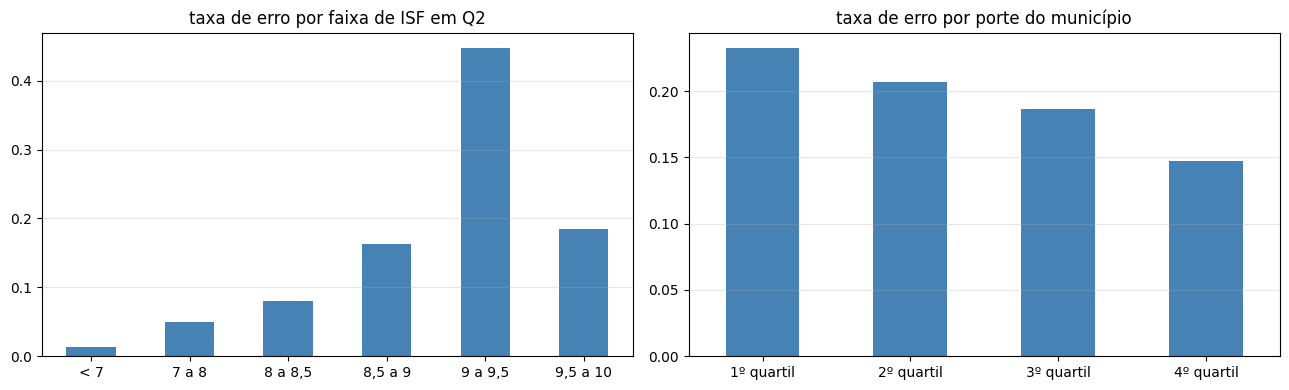

,municípios,taxa de erro,falsos negativos,falsos positivos
isf,,,,
< 7,575,0.014,0,8
7 a 8,656,0.050,3,30
"8 a 8,5",682,0.081,10,45
"8,5 a 9",949,0.163,40,115
"9 a 9,5",1237,0.447,494,59
"9,5 a 10",1468,0.185,267,4


In [44]:
erro = (previsto_final != y_teste)
porte_te = pd.qcut(X_teste['log_pop'], 4, labels=['1º quartil', '2º quartil', '3º quartil', '4º quartil'])
faixa_isf = pd.cut(X_teste['isf'], [0, 7, 8, 8.5, 9, 9.5, 10.01], labels=['< 7', '7 a 8', '8 a 8,5', '8,5 a 9', '9 a 9,5', '9,5 a 10'])

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
erro.groupby(faixa_isf, observed=True).mean().plot.bar(ax=eixos[0], color='steelblue', rot=0)
eixos[0].set_title('taxa de erro por faixa de ISF em Q2')
eixos[0].set_xlabel('')
erro.groupby(porte_te, observed=True).mean().plot.bar(ax=eixos[1], color='steelblue', rot=0)
eixos[1].set_title('taxa de erro por porte do município')
eixos[1].set_xlabel('')
for eixo in eixos:
    eixo.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({
    'municípios': faixa_isf.value_counts().sort_index(),
    'taxa de erro': erro.groupby(faixa_isf, observed=True).mean(),
    'falsos negativos': falso_negativo.groupby(faixa_isf, observed=True).sum(),
    'falsos positivos': falso_positivo.groupby(faixa_isf, observed=True).sum(),
}).round(3)

Os erros se concentram logo acima do corte. A taxa de erro é de 1,4% para municípios com ISF abaixo de 7 e de 44,7% na faixa de 9 a 9,5, que tem 1.237 municípios e 494 dos 814 falsos negativos. O erro também é maior nos municípios pequenos: 23% no quartil de menor população, contra 15% no de maior.

Variação mediana de cada indicador entre Q2 e Q3, separando falsos negativos, acertos da classe `abaixo_90` e municípios que ficaram com 9 ou mais:

In [45]:
# Variação mediana de cada indicador entre Q2 e Q3, por tipo de resultado
q2 = mun[mun['ds_quadrimestre'] == '2024Q2'].set_index('ibge')
indicadores = list(METAS.index)
delta = (q3.loc[X_teste.index, indicadores] - q2.loc[X_teste.index, indicadores])
pd.DataFrame({
    'falsos negativos': delta[falso_negativo].median(),
    'acertos que ficaram abaixo': delta[(y_teste == 1) & (previsto_final == 1)].median(),
    'ficaram com 9 ou mais': delta[y_teste == 0].median(),
}).round(1).rename_axis('variação mediana Q2 -> Q3 (pontos)')

,falsos negativos,acertos que ficaram abaixo,ficaram com 9 ou mais
variação mediana Q2 -> Q3 (pontos),,,
ind1,-9.0,-3.0,0.0
ind2,-8.0,-4.0,0.0
ind3,-13.0,-4.0,-2.0
ind4,-1.0,0.0,0.0
ind5,-6.0,0.0,0.0
ind7,-10.0,-3.0,-2.0


Nos falsos negativos, os indicadores caíram muito e quase todos ao mesmo tempo: de 8 a 13 pontos nos três indicadores da gestante e 10 pontos no diabetes. Nos municípios que caíram e foram previstos, a queda mediana foi de 3 a 4 pontos. Os falsos negativos são quedas grandes e generalizadas, que não aparecem nos atributos do quadrimestre anterior.

## 11. Análise crítica

### Pontos fortes

- O ISF é recalculado a partir da regra oficial e conferido com o exemplo do manual, em vez de vir de uma coluna pronta.
- O teste é temporal, e a escolha de modelo, hiperparâmetros e limiar foi feita só com o treino.
- Todos os resultados são comparados com um baseline forte, e não só com uma previsão aleatória.
- Usado para ordenar municípios por risco, o modelo encontra quedas 2,2 vezes mais que a média do grupo entre os 100 primeiros.
- O modelo treina em menos de um segundo e varia pouco entre as dobras (desvio de 0,003).

### Limitações

- A melhora sobre o baseline é pequena: 0,005 em balanced accuracy e 0,013 em AUC no teste.
- O modelo não prevê pioras gerais como a de Q3, que não estavam nos dados de Q2.
- Entre os municípios com ISF 9 ou mais, o modelo previu só 122 das 885 quedas com limiar 0,5.
- Com três quadrimestres há um único par para treino e um para teste. A validação cruzada é feita dentro do mesmo período e fica otimista (0,864 contra 0,821 no teste).
- Sem o indicador 6, o ISF tem soma de pesos 8 em vez de 10, e o corte em 9 não corresponde exatamente ao do pagamento.

### Qualidade dos dados

- Não há valores ausentes nem duplicados, e o resultado de cada indicador bate com numerador sobre denominador.
- Falta o indicador 6, e quatro municípios não aparecem em algum quadrimestre.
- Municípios pequenos têm denominadores pequenos, o que gera muitos resultados em 0 e 100: com 12 gestantes, uma a mais muda o indicador em 8 pontos.
- Algumas inconsistências vêm da forma como os dados são produzidos: denominador zero com resultado 0 (7 linhas), identificado até 18 vezes maior que o estimado e cadastro maior que a população em 70,6% dos registros.
- A base não tem informações como número de equipes, troca de profissionais ou repasses, que poderiam explicar as quedas que o modelo não prevê.

### Problemas encontrados

| Problema | Solução |
| --- | --- |
| Prever o ISF do mesmo quadrimestre só reproduziria a fórmula | usar o ISF do quadrimestre seguinte como alvo |
| Proporção do target diferente no treino (51%) e no teste (63%) | balanced accuracy como métrica principal |
| Apenas três quadrimestres disponíveis | validação cruzada dentro do treino, comparada depois com o teste |
| Random Forest 0,001 à frente no teste | manter a escolha feita na validação cruzada |
| Grade de hiperparâmetros com ganho de 0,0025 e desvio maior | manter a configuração inicial |
| CatBoost cria a pasta `catboost_info/` a cada treino | `allow_writing_files=False` |

### Melhorias futuras

1. Incluir 2022 e 2023, que estão no mesmo portal. Com mais quadrimestres teríamos vários pares de treino, poderíamos validar com janela deslizante e criar atributos de tendência, como a variação do ISF nos últimos quadrimestres.
2. Criar atributos de variabilidade, como o desvio do indicador de diabetes ao longo do tempo, para separar correção de registro de mudança real no atendimento.
3. Cruzar com outras bases por município: equipes e profissionais (CNES), cobertura da atenção primária, IDH e repasses.
4. Incluir o indicador 6, se for possível obtê-lo, para calcular o ISF completo.
5. Definir o limiar a partir do custo de acompanhar um município e do valor do incentivo perdido, e calibrar as probabilidades.
6. Testar um modelo treinado só com os municípios que têm ISF 9 ou mais, que é o grupo em que o baseline não ajuda.

## 12. Conclusões

| # | Pergunta | Resposta |
| --- | --- | --- |
| 1 | Qual problema estamos tentando resolver? | Prever, ao fim de um quadrimestre, quais municípios terão ISF abaixo de 9 no quadrimestre seguinte e vão receber menos de 90% do incentivo de desempenho do Previne Brasil |
| 2 | Que dados utilizamos? | Indicadores de desempenho do Previne Brasil (Ministério da Saúde, CC BY-ND 3.0): 300.732 linhas dos três quadrimestres de 2024, por município, indicador e visão de equipe |
| 3 | O que descobrimos nos dados? | O ISF muda pouco entre quadrimestres (correlação de 0,81 a 0,84), mas caiu ao longo de 2024. Citopatológico, vacinação e diabetes são as metas que a maioria não atinge. Municípios pequenos variam mais. A base não tem ausentes nem duplicados |
| 4 | Como preparamos os dados? | Filtramos a visão de equipes válidas, recalculamos o ISF pela regra oficial, montamos uma linha por município e quadrimestre, criamos oito features, aplicamos one-hot na UF e separamos treino (Q1 → Q2) e teste (Q2 → Q3) |
| 5 | Quais modelos testamos? | Random Forest, XGBoost, LightGBM, CatBoost e um ensemble dos três boosting, comparados com um baseline que repete o resultado atual |
| 6 | Como comparamos os modelos? | Validação cruzada estratificada de 5 dobras no treino, comparação dobra a dobra com o baseline, curva ROC, análise por porte e no grupo com ISF 9 ou mais. O teste só foi usado depois da escolha |
| 7 | Qual métrica escolhemos? | Balanced accuracy, porque a proporção do target muda entre treino e teste. Também acompanhamos recall de `abaixo_90` e AUC |
| 8 | Qual foi o melhor modelo? | XGBoost: 0,864 de balanced accuracy na validação cruzada e 0,821 no teste (baseline: 0,816), com AUC de 0,900 e recall de 0,767 no teste |
| 9 | Por que escolhemos esse modelo? | Teve a maior balanced accuracy e o menor desvio na validação, superou o baseline nas cinco dobras, foi o melhor no grupo com ISF 9 ou mais e treina em menos de um segundo |
| 10 | Quais são suas limitações? | Ganho pequeno sobre o baseline, não prevê pioras gerais como a de Q3, recall baixo no grupo com ISF 9 ou mais, um único par de treino e ISF sem o indicador 6 |
| 11 | Quais são as oportunidades de melhoria? | Usar os dados de 2022 e 2023, criar atributos de tendência e de variabilidade, cruzar com dados de equipes e cobertura, incluir o indicador 6 e definir o limiar pelo custo |

O ISF do quadrimestre atual é o melhor preditor do próximo, e o modelo melhora pouco essa previsão. A contribuição dele está em ordenar os municípios que hoje têm ISF 9 ou mais pelo risco de queda (71 dos 100 primeiros caíram) e em mostrar que citopatológico e diabetes são os indicadores mais ligados a essas quedas.

### Saídas

Os números usados nos slides são gravados em `ml/saidas/`, que não é versionada.

In [46]:
# Resultados usados nos slides, gravados em ml/saidas/ (fora do Git)
saida = RAIZ / 'ml' / 'saidas'
saida.mkdir(exist_ok=True)
pd.DataFrame({'cv_media': media.loc[ordem, 'balanced accuracy']}).join(resultado_teste).to_csv(saida / 'previne_comparacao.csv')
cv_res.to_csv(saida / 'previne_cv_dobras.csv', index=False)
print('gravado em', saida)

gravado em C:\Users\joaop\OneDrive\Área de Trabalho\projeto-6\ml\saidas
